<a href="https://colab.research.google.com/github/saatour/GW170817/blob/main/20261013_EAGLE_simulation_analysis_Chapter6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install numpy pandas matplotlib scipy astropy healpy requests

In [3]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import healpy as hp
import requests

from astropy.io import fits
from scipy.integrate import cumulative_trapezoid

# Create local data directory
DATA = Path("data")
DATA.mkdir(exist_ok=True)

# GW190814 localisation file
SKYMAP_URL = (
    "https://dcc.ligo.org/LIGO-P2000230/public/"
    "GW190814_skymap.fits.gz"
)

SKYMAP_FILE = DATA / "GW190814_skymap.fits.gz"

# Credible probability level
CREDIBLE = 0.90

print("Working directory:", Path.cwd().resolve())
print("Target credible level:", CREDIBLE)

Working directory: /content
Target credible level: 0.9


In [4]:
if not SKYMAP_FILE.exists():

    response = requests.get(
        SKYMAP_URL,
        timeout=120
    )

    response.raise_for_status()

    SKYMAP_FILE.write_bytes(response.content)

# Confirm file exists
assert SKYMAP_FILE.exists()
assert SKYMAP_FILE.stat().st_size > 1000

# Record a checksum for reproducibility
sha256 = hashlib.sha256(
    SKYMAP_FILE.read_bytes()
).hexdigest()

print("File:", SKYMAP_FILE)
print("File size:", SKYMAP_FILE.stat().st_size, "bytes")
print("SHA256:", sha256)

# Inspect the FITS structure
with fits.open(SKYMAP_FILE) as hdul:

    hdul.info()

    print("\nAvailable columns:")
    print(hdul[1].columns.names)

    print("\nHEALPix ordering:")
    print(hdul[1].header.get("ORDERING"))

File: data/GW190814_skymap.fits.gz
File size: 1472321 bytes
SHA256: 468ec8032ed11458ff9ef3c8735a039fcb0ead37f7a57be9c133f3df2dd8757e
Filename: data/GW190814_skymap.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU     32   12582912R x 4C   [D, D, D, D]   

Available columns:
['PROB', 'DISTMU', 'DISTSIGMA', 'DISTNORM']

HEALPix ordering:
NESTED


In [5]:
with fits.open(SKYMAP_FILE, memmap=False) as hdul:

    header = hdul[1].header
    table = hdul[1].data

    required_columns = {
        "PROB",
        "DISTMU",
        "DISTSIGMA",
        "DISTNORM"
    }

    available_columns = set(table.names)

    assert required_columns.issubset(available_columns), (
        f"Missing columns: "
        f"{required_columns - available_columns}"
    )

    nside = int(header["NSIDE"])
    ordering = str(header.get("ORDERING", "")).upper()

    prob = np.asarray(table["PROB"], dtype=float)
    distmu = np.asarray(table["DISTMU"], dtype=float)
    distsigma = np.asarray(table["DISTSIGMA"], dtype=float)
    distnorm = np.asarray(table["DISTNORM"], dtype=float)

# Validate prob map
assert len(prob) == hp.nside2npix(nside)
assert np.all(np.isfinite(prob))
assert np.all(prob >= 0)
assert np.isclose(prob.sum(), 1.0, atol=1e-3)

print("NSIDE:", nside)
print("Ordering:", ordering)
print("Number of pixels:", len(prob))
print("Total probability:", prob.sum())

NSIDE: 1024
Ordering: NESTED
Number of pixels: 12582912
Total probability: 0.9999999999999997


In [6]:
from astropy.cosmology import Planck18, z_at_value
import astropy.units as u

# We are calculating a true 3D credible region,
# not combining separate sky and distance intervals.

CREDIBLE = 0.90

# HEALPix pixel solid angle
pixel_area_sr = hp.nside2pixarea(nside)

# Pixels with valid conditional distance information
valid = (
    np.isfinite(prob)
    & (prob > 0)
    & np.isfinite(distmu)
    & np.isfinite(distsigma)
    & np.isfinite(distnorm)
    & (distsigma > 0)
    & (distnorm > 0)
)

print("Probability with valid distance information:",
      prob[valid].sum())

assert prob[valid].sum() > 0.999, (
    "Too much probability is missing distance information."
)

# Set a luminosity-distance range covering the posterior
distance_max = np.max(
    distmu[valid] + 8 * distsigma[valid]
)

# Radial discretisation
N_RADIAL = 2400

dl_edges = np.linspace(
    0.0,
    distance_max,
    N_RADIAL + 1
)

dl_mid = 0.5 * (dl_edges[:-1] + dl_edges[1:])
dl_width = np.diff(dl_edges)

# Convert luminosity-distance edges to comoving distance.
# We use Planck18 as the reference cosmology.

z_max = z_at_value(
    Planck18.luminosity_distance,
    distance_max * u.Mpc,
    zmax=10
)

z_lookup = np.linspace(
    0,
    float(z_max) * 1.01,
    5000
)

dl_lookup = Planck18.luminosity_distance(
    z_lookup
).to_value(u.Mpc)

dc_lookup = Planck18.comoving_distance(
    z_lookup
).to_value(u.Mpc)

dc_edges = np.interp(
    dl_edges,
    dl_lookup,
    dc_lookup
)

# Exact comoving shell volume per steradian
shell_volume = (
    dc_edges[1:]**3 - dc_edges[:-1]**3
) / 3.0

# Volume of one HEALPix angular pixel
# intersected with each radial shell
voxel_volume = pixel_area_sr * shell_volume

print(f"HEALPix NSIDE: {nside}")
print(f"Valid sky pixels: {valid.sum():,}")
print(f"Maximum luminosity distance: {distance_max:.2f} Mpc")
print(f"Radial shells: {N_RADIAL}")
print(f"Maximum comoving distance: {dc_edges[-1]:.2f} Mpc")

Probability with valid distance information: 0.9999999999999999
HEALPix NSIDE: 1024
Valid sky pixels: 171,136
Maximum luminosity distance: 708.56 Mpc
Radial shells: 2400
Maximum comoving distance: 618.99 Mpc


In [7]:
# Extract valid pixel data
p = prob[valid]
mu = distmu[valid]
sigma = distsigma[valid]
norm = distnorm[valid]

# Probability density per comoving Mpc^3 is used
# to define the highest-posterior-density region.

# Logarithmic bins for numerical density thresholding
density_edges = np.logspace(-40, 0, 12001)
n_bins = len(density_edges) - 1

prob_hist = np.zeros(n_bins)
volume_hist = np.zeros(n_bins)

total_probability = 0.0
outside_density_range = 0.0

CHUNK_SIZE = 128

for start in range(0, len(p), CHUNK_SIZE):

    end = min(start + CHUNK_SIZE, len(p))

    pc = p[start:end, None]
    muc = mu[start:end, None]
    sigc = sigma[start:end, None]
    normc = norm[start:end, None]

    # Conditional luminosity-distance posterior:
    # p(D_L | sky) proportional to
    # D_L^2 exp[-(D_L - mu)^2 / (2 sigma^2)]

    exponent = -0.5 * (
        (dl_mid[None, :] - muc) / sigc
    )**2

    conditional_pdf = (
        normc
        * dl_mid[None, :]**2
        * np.exp(exponent)
        / (np.sqrt(2 * np.pi) * sigc)
    )

    # Joint probability in each sky/radial voxel
    voxel_prob = (
        pc
        * conditional_pdf
        * dl_width[None, :]
    )

    total_probability += voxel_prob.sum()

    # Probability density per unit comoving volume
    density = voxel_prob / voxel_volume[None, :]

    # Assign each voxel to a density histogram bin
    indices = np.searchsorted(
        density_edges,
        density,
        side="right"
    ) - 1

    in_range = (
        (indices >= 0)
        & (indices < n_bins)
        & np.isfinite(density)
    )

    outside_density_range += voxel_prob[~in_range].sum()

    # Histogram of posterior probability
    prob_hist += np.bincount(
        indices[in_range],
        weights=voxel_prob[in_range],
        minlength=n_bins
    )

    # Histogram of geometric comoving volume
    volumes = np.broadcast_to(
        voxel_volume[None, :],
        voxel_prob.shape
    )

    volume_hist += np.bincount(
        indices[in_range],
        weights=volumes[in_range],
        minlength=n_bins
    )

print(f"Integrated posterior probability: {total_probability:.6f}")
print(f"Probability outside density bins: {outside_density_range:.3e}")

assert np.isclose(
    total_probability, 1.0, atol=0.005
), "Posterior integration is not sufficiently normalised."

assert outside_density_range < 1e-6, (
    "Density histogram bounds are insufficient."
)

Integrated posterior probability: 1.000000
Probability outside density bins: 1.594e-36


In [8]:
# Numerical probability normalisation
prob_hist_normalised = prob_hist / total_probability

# Reverse arrays: highest density first
p_desc = prob_hist_normalised[::-1]
v_desc = volume_hist[::-1]

cumulative_probability = np.cumsum(p_desc)
cumulative_volume = np.cumsum(v_desc)

# First bin reaching the requested probability
idx = np.searchsorted(
    cumulative_probability,
    CREDIBLE
)

assert idx < len(p_desc), (
    "Could not enclose the requested probability."
)

# Probability enclosed before the boundary bin
p_before = (
    cumulative_probability[idx - 1]
    if idx > 0 else 0.0
)

# Volume enclosed before the boundary bin
v_before = (
    cumulative_volume[idx - 1]
    if idx > 0 else 0.0
)

# Fraction of the boundary density bin needed
fraction = (
    (CREDIBLE - p_before) / p_desc[idx]
)

# Approximate HPD volume,
# interpolating inside the boundary density bin
V90 = v_before + fraction * v_desc[idx]

# Equivalent cubic volume
L_cube = V90**(1.0 / 3.0)

print("=" * 55)
print("GW190814 THREE-DIMENSIONAL LOCALISATION")
print("=" * 55)

print(f"Credible probability: {CREDIBLE:.1%}")

print(
    f"90% HPD comoving volume: "
    f"{V90:,.2f} cMpc^3"
)

print(
    f"Equivalent EAGLE cube side: "
    f"{L_cube:.3f} cMpc"
)

print(
    f"Posterior probability represented: "
    f"{total_probability:.6f}"
)

print("=" * 55)

# Save results for subsequent notebook cells
volume_results = {
    "event": "GW190814",
    "credible_level": CREDIBLE,
    "definition": "3D highest-posterior-density region",
    "cosmology": "Planck18",
    "volume_comoving_mpc3": float(V90),
    "cube_side_comoving_mpc": float(L_cube),
    "radial_shells": N_RADIAL,
    "integrated_probability": float(total_probability),
    "skymap_sha256": sha256
}

output_file = DATA / "GW190814_volume_results.json"

with open(output_file, "w") as f:
    json.dump(volume_results, f, indent=2)

print(f"Results saved to: {output_file}")

GW190814 THREE-DIMENSIONAL LOCALISATION
Credible probability: 90.0%
90% HPD comoving volume: 31,665.93 cMpc^3
Equivalent EAGLE cube side: 31.637 cMpc
Posterior probability represented: 1.000000
Results saved to: data/GW190814_volume_results.json


In [9]:
%pip install ligo.skymap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.6/140.6 kB 5.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.8/87.8 kB 6.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.7/21.7 MB 58.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.4/193.4 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 98.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 83.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.6/168.6 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.1/114.1 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [10]:
from ligo.skymap.distance import conditional_pdf

# Select 100 valid sky pixels reproducibly
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    np.flatnonzero(valid),
    size=100,
    replace=False
)

# Choose a range of luminosity distances
test_distances = np.linspace(
    1.0,
    distance_max,
    500
)

# Official LIGO implementation
official_pdf = conditional_pdf(
    test_distances[None, :],
    distmu[sample_indices, None],
    distsigma[sample_indices, None],
    distnorm[sample_indices, None]
)

# Our implementation
mu_test = distmu[sample_indices, None]
sigma_test = distsigma[sample_indices, None]
norm_test = distnorm[sample_indices, None]

our_pdf = (
    norm_test
    * test_distances[None, :]**2
    * np.exp(
        -0.5 * (
            (test_distances[None, :] - mu_test)
            / sigma_test
        )**2
    )
    / (np.sqrt(2 * np.pi) * sigma_test)
)

# Compare numerical implementations
np.testing.assert_allclose(
    our_pdf,
    official_pdf,
    rtol=1e-10,
    atol=1e-14
)

print("PASS: Conditional distance posterior matches ligo.skymap.")

/usr/local/lib/python3.13/dist-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


PASS: Conditional distance posterior matches ligo.skymap.


In [11]:
%pip install eaglesqltools

In [12]:
import eagleSqlTools as sql
import getpass

# Enter EAGLE credentials interactively.
# These are not written into the notebook.

EAGLE_USER = "nmq680"

EAGLE_PASSWORD = "zw59ha64"

# Connect to the EAGLE database
con = sql.connect(
    EAGLE_USER,
    password=EAGLE_PASSWORD
)

# Remove the password variable after connecting
del EAGLE_PASSWORD

print("Connected to the EAGLE database.")

Connected to the EAGLE database.


In [13]:
import numpy as np
import pandas as pd

SIMULATION = "RefL0100N1504"
SNAPSHOT = 28
BOX_SIZE_CMPC = 100.0
APERTURE_PKPC = 30
EXTRACTION_MASS_FLOOR = 1e8

# Small database query to test access
test_query = """
SELECT TOP 5
    SH.GalaxyID,
    SH.SnapNum,
    SH.CentreOfPotential_x AS x,
    SH.CentreOfPotential_y AS y,
    SH.CentreOfPotential_z AS z,
    AP.Mass_Star AS Mstar_30pkpc,
    AP.SFR AS SFR_30pkpc
FROM
    RefL0100N1504_SubHalo AS SH,
    RefL0100N1504_Aperture AS AP
WHERE
    SH.GalaxyID = AP.GalaxyID
    AND SH.SnapNum = 28
    AND AP.ApertureSize = 30
    AND AP.Mass_Star > 1e8
ORDER BY
    AP.Mass_Star DESC
"""

test_result = sql.execute_query(con, test_query)

test_df = pd.DataFrame(
    np.atleast_1d(test_result)
)

print("Rows returned:", len(test_df))
print("\nColumns:")
print(test_df.columns.tolist())

display(test_df)

Rows returned: 5

Columns:
['GalaxyID', 'SnapNum', 'x', 'y', 'z', 'Mstar_30pkpc', 'SFR_30pkpc']


,GalaxyID,SnapNum,x,y,z,Mstar_30pkpc,SFR_30pkpc
0,21242350,28,11.369572,80.663208,54.190159,4.647067e+11,2.421584
1,21730535,28,52.799755,4.919716,20.063511,4.485735e+11,2.198527
2,21109760,28,17.108519,79.767769,52.717827,4.196701e+11,3.514611
3,21986361,28,76.670509,89.474174,41.884659,3.729405e+11,0.851944
4,19701409,28,84.921928,47.613113,7.973583,3.587923e+11,2.074490


In [14]:
# Full EAGLE galaxy catalogue
# RefL0100N1504, snapshot 28 (z = 0)
# Stellar masses and SFRs measured within 30 pkpc

catalogue_query = """
SELECT
    SH.GalaxyID,
    SH.SnapNum,

    SH.CentreOfPotential_x AS x,
    SH.CentreOfPotential_y AS y,
    SH.CentreOfPotential_z AS z,

    AP.Mass_Star AS Mstar_30pkpc,
    AP.Mass_Gas AS Mgas_30pkpc,
    AP.SFR AS SFR_30pkpc,

    SH.GroupID,
    SH.SubGroupNumber

FROM
    RefL0100N1504_SubHalo AS SH,
    RefL0100N1504_Aperture AS AP

WHERE
    SH.GalaxyID = AP.GalaxyID
    AND SH.SnapNum = 28
    AND AP.ApertureSize = 30
    AND AP.Mass_Star > 1e8
"""

catalogue_result = sql.execute_query(
    con,
    catalogue_query
)

eagle = pd.DataFrame(
    np.atleast_1d(catalogue_result)
)

print(f"Retrieved {len(eagle):,} galaxies.")

display(eagle.head())

Retrieved 40,076 galaxies.


,GalaxyID,SnapNum,x,y,z,Mstar_30pkpc,Mgas_30pkpc,SFR_30pkpc,GroupID,SubGroupNumber
0,8633758,28,64.417908,81.101913,68.873558,1.096747e+10,8.495143e+08,0.002313,28000000000698,1
1,8675491,28,16.569355,65.467125,4.366856,3.394720e+10,7.419656e+09,1.955878,28000000000835,0
2,8702729,28,19.211592,79.831993,47.361748,5.925151e+09,1.006599e+09,0.626983,28000000000927,1
3,8708413,28,24.610020,7.245740,3.062680,9.694703e+09,5.477012e+09,0.306497,28000000000941,1
4,8738765,28,10.676959,28.348660,19.665430,7.038249e+09,8.714895e+08,0.132999,28000000000995,1


In [15]:
# Check required columns
required = [
    "GalaxyID",
    "SnapNum",
    "x", "y", "z",
    "Mstar_30pkpc",
    "Mgas_30pkpc",
    "SFR_30pkpc",
    "GroupID",
    "SubGroupNumber"
]

assert all(col in eagle.columns for col in required)

# Check identifiers
assert eagle["GalaxyID"].is_unique, (
    "Duplicate galaxy identifiers detected."
)

# Confirm correct snapshot
assert (eagle["SnapNum"] == 28).all()

# Check finite positions and stellar masses
assert np.isfinite(
    eagle[["x", "y", "z", "Mstar_30pkpc"]]
    .to_numpy(dtype=float)
).all()

# Check simulation coordinates
assert (
    (eagle[["x", "y", "z"]] >= 0)
    & (eagle[["x", "y", "z"]] < 100)
).all().all()

# Check initial extraction threshold
assert (eagle["Mstar_30pkpc"] > 1e8).all()

# Check SFR values
assert np.isfinite(eagle["SFR_30pkpc"]).all()
assert (eagle["SFR_30pkpc"] >= 0).all()

# Report relevant properties
print("EAGLE PARENT CATALOGUE")
print("-" * 45)

print(f"Galaxies: {len(eagle):,}")
print(f"Unique IDs: {eagle['GalaxyID'].nunique():,}")

print(
    "Stellar mass range:",
    f"{eagle['Mstar_30pkpc'].min():.3e}",
    "to",
    f"{eagle['Mstar_30pkpc'].max():.3e}",
    "Msun"
)

print(
    "Zero-SFR galaxies:",
    f"{(eagle['SFR_30pkpc'] == 0).sum():,}"
)

print(
    "Non-finite gas masses:",
    f"{(~np.isfinite(eagle['Mgas_30pkpc'])).sum():,}"
)

# Save reproducible local copy
catalogue_path = DATA / "EAGLE_RefL0100N1504_snap28_parent.csv"

eagle.to_csv(catalogue_path, index=False)

print("\nSaved:", catalogue_path)

EAGLE PARENT CATALOGUE
---------------------------------------------
Galaxies: 40,076
Unique IDs: 40,076
Stellar mass range: 1.000e+08 to 4.647e+11 Msun
Zero-SFR galaxies: 16,833
Non-finite gas masses: 0

Saved: data/EAGLE_RefL0100N1504_snap28_parent.csv


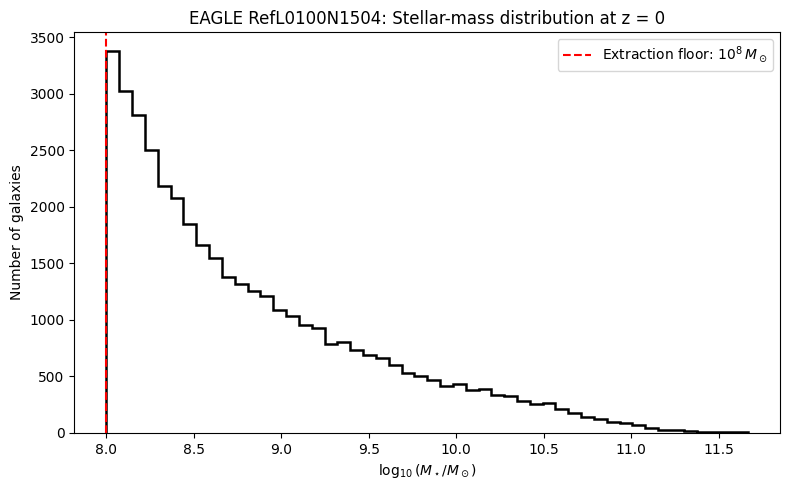

In [16]:
eagle["logMstar"] = np.log10(
    eagle["Mstar_30pkpc"]
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    eagle["logMstar"],
    bins=50,
    histtype="step",
    linewidth=1.8,
    color="black"
)

ax.axvline(
    8.0,
    linestyle="--",
    color="red",
    label=r"Extraction floor: $10^8\,M_\odot$"
)

ax.set_xlabel(
    r"$\log_{10}(M_\star/M_\odot)$"
)

ax.set_ylabel("Number of galaxies")

ax.set_title(
    "EAGLE RefL0100N1504: "
    "Stellar-mass distribution at z = 0"
)

ax.legend()

plt.tight_layout()
plt.show()

In [17]:
# Candidate stellar-mass thresholds
log_mass_limits = np.array([
    8.0, 8.5, 9.0, 9.5, 10.0
])

# EAGLE box volume in comoving Mpc^3
box_volume = BOX_SIZE_CMPC**3

# GW190814 90% HPD-equivalent volume
mock_volume = V90

results = []

for log_limit in log_mass_limits:

    mass_limit = 10**log_limit

    selected = eagle[
        eagle["Mstar_30pkpc"] > mass_limit
    ]

    n_galaxies = len(selected)

    number_density = n_galaxies / box_volume

    # Mean expected count in an equivalent volume
    expected_count = number_density * mock_volume

    results.append({
        "logM_limit": log_limit,
        "N_box": n_galaxies,
        "number_density_cMpc3": number_density,
        "expected_N_mock": expected_count
    })

threshold_df = pd.DataFrame(results)

display(
    threshold_df.round({
        "number_density_cMpc3": 5,
        "expected_N_mock": 1
    })
)

,logM_limit,N_box,number_density_cMpc3,expected_N_mock
0,8.0,40076,0.04008,1269.0
1,8.5,22580,0.02258,715.0
2,9.0,13200,0.01320,418.0
3,9.5,7241,0.00724,229.3
4,10.0,3562,0.00356,112.8


In [18]:
# Provisional primary stellar-mass threshold
LOG_MASS_MIN = 9.0
MASS_MIN = 10**LOG_MASS_MIN

# Select galaxies above threshold
eagle_science = eagle.loc[
    eagle["Mstar_30pkpc"] >= MASS_MIN
].copy()

# Fix random seed for reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Cube side length from GW190814 3D volume
L = V90**(1 / 3)

# Uniformly position the cube entirely inside
# the EAGLE simulation box
cube_origin = rng.uniform(
    0,
    BOX_SIZE_CMPC - L,
    size=3
)

cube_upper = cube_origin + L

# Select galaxies within the cube
position_columns = ["x", "y", "z"]
positions = eagle_science[position_columns].to_numpy()

inside = np.all(
    (positions >= cube_origin)
    & (positions < cube_upper),
    axis=1
)

reference_cube = eagle_science.loc[inside].copy()

print("REFERENCE EAGLE CUBE")
print("-" * 45)
print(f"Random seed: {RANDOM_SEED}")
print(f"Stellar-mass threshold: 10^{LOG_MASS_MIN:.1f} Msun")
print(f"Cube side length: {L:.3f} cMpc")
print(f"Cube volume: {L**3:,.2f} cMpc³")
print(f"Cube origin: {cube_origin.round(3)}")
print(f"Galaxies selected: {len(reference_cube):,}")

display(reference_cube.head())

REFERENCE EAGLE CUBE
---------------------------------------------
Random seed: 42
Stellar-mass threshold: 10^9.0 Msun
Cube side length: 31.637 cMpc
Cube volume: 31,665.93 cMpc³
Cube origin: [52.91  30.003 58.696]
Galaxies selected: 402


,GalaxyID,SnapNum,x,y,z,Mstar_30pkpc,Mgas_30pkpc,SFR_30pkpc,GroupID,SubGroupNumber,logMstar
25,9914653,28,64.517891,48.769932,70.135315,5.557496e+09,7.016629e+09,0.331959,28000000001761,0,9.744879
64,10944677,28,78.062775,37.070679,62.934540,8.115927e+09,2.288659e+09,0.394738,28000000002685,0,9.909338
75,11108040,28,60.322689,46.731213,71.328751,5.104611e+09,4.735187e+09,0.505829,28000000002910,0,9.707963
98,11359928,28,54.389301,40.197376,63.420010,1.294219e+09,5.586505e+09,0.234124,28000000003315,0,9.112008
156,12787176,28,70.506050,55.757988,73.544815,4.663042e+09,9.471797e+08,0.358010,28000000000056,5,9.668670


In [19]:
# Confirm that the reference cube satisfies
# all of our selection requirements.

assert reference_cube["GalaxyID"].is_unique

assert (
    reference_cube["Mstar_30pkpc"] >= MASS_MIN
).all()

assert np.all(
    (reference_cube[["x", "y", "z"]].to_numpy()
     >= cube_origin)
    &
    (reference_cube[["x", "y", "z"]].to_numpy()
     < cube_upper)
)

# Summarise the galaxy population

n_gal = len(reference_cube)
n_zero_sfr = (reference_cube["SFR_30pkpc"] == 0).sum()

summary = pd.Series({
    "Galaxy count": n_gal,
    "Number density (cMpc^-3)": n_gal / V90,
    "Median log stellar mass": reference_cube["logMstar"].median(),
    "Maximum log stellar mass": reference_cube["logMstar"].max(),
    "Median SFR (Msun/yr)": reference_cube["SFR_30pkpc"].median(),
    "Zero-SFR fraction": n_zero_sfr / n_gal,
    "Distinct GroupIDs": reference_cube["GroupID"].nunique()
})

display(summary.to_frame("Value"))

,Value
Galaxy count,402.000000
Number density (cMpc^-3),0.012695
Median log stellar mass,9.538293
Maximum log stellar mass,11.410273
Median SFR (Msun/yr),0.133528
Zero-SFR fraction,0.181592
Distinct GroupIDs,237.000000


In [20]:
# Save the actual reference galaxy population
reference_path = DATA / "EAGLE_reference_cube_seed42.csv"

reference_cube.to_csv(
    reference_path,
    index=False
)

# Record the exact configuration
cube_config = {
    "simulation": SIMULATION,
    "snapshot": SNAPSHOT,
    "redshift": 0.0,
    "stellar_mass_threshold_msun": float(MASS_MIN),
    "random_seed": RANDOM_SEED,
    "box_size_comoving_mpc": BOX_SIZE_CMPC,
    "cube_origin_comoving_mpc": cube_origin.tolist(),
    "cube_upper_comoving_mpc": cube_upper.tolist(),
    "cube_side_comoving_mpc": float(L),
    "cube_volume_comoving_mpc3": float(L**3),
    "galaxy_count": int(len(reference_cube)),
    "boundary_handling": "cube entirely inside simulation box"
}

config_path = DATA / "EAGLE_reference_cube_config.json"

with open(config_path, "w") as f:
    json.dump(cube_config, f, indent=2)

print("Reference cube saved:", reference_path)
print("Configuration saved:", config_path)

Reference cube saved: data/EAGLE_reference_cube_seed42.csv
Configuration saved: data/EAGLE_reference_cube_config.json


In [21]:
def sample_periodic_cube(
    catalogue,
    origin,
    side_length,
    box_size=100.0
):
    """
    Select galaxies inside a cube in a periodic
    cosmological simulation box.

    Parameters
    ----------
    catalogue : pandas.DataFrame
        Galaxy catalogue containing x, y, z.
    origin : array-like, length 3
        Cube origin in comoving Mpc.
    side_length : float
        Cube side length in comoving Mpc.
    box_size : float
        Simulation box side length in comoving Mpc.

    Returns
    -------
    pandas.DataFrame
        Galaxies contained in the periodic cube.
    """

    origin = np.asarray(origin, dtype=float)

    assert origin.shape == (3,)
    assert 0 < side_length <= box_size

    positions = catalogue[
        ["x", "y", "z"]
    ].to_numpy(dtype=float)

    # Position relative to the cube origin,
    # wrapping across periodic boundaries
    relative = (
        positions - origin
    ) % box_size

    inside = np.all(
        relative < side_length,
        axis=1
    )

    return catalogue.loc[inside].copy()

In [22]:
# Repeat reference cube selection using
# the periodic implementation

periodic_reference = sample_periodic_cube(
    catalogue=eagle_science,
    origin=cube_origin,
    side_length=L,
    box_size=BOX_SIZE_CMPC
)

original_ids = set(reference_cube["GalaxyID"])
periodic_ids = set(periodic_reference["GalaxyID"])

assert original_ids == periodic_ids, (
    "Periodic and non-periodic selections differ."
)

print("PASS: Periodic selection reproduces reference cube.")
print("Galaxy count:", len(periodic_reference))

PASS: Periodic selection reproduces reference cube.
Galaxy count: 402


In [23]:
# Artificial catalogue for boundary testing
test_galaxies = pd.DataFrame({
    "GalaxyID": [1, 2, 3, 4],
    "x": [98.0, 2.0, 50.0, 99.0],
    "y": [98.0, 2.0, 50.0, 1.0],
    "z": [98.0, 2.0, 50.0, 99.0]
})

# Cube extends from 95 to 105 on each axis,
# wrapping around the 100 cMpc boundary.
test_cube = sample_periodic_cube(
    catalogue=test_galaxies,
    origin=[95.0, 95.0, 95.0],
    side_length=10.0,
    box_size=100.0
)

# Galaxies 1, 2 and 4 should be included.
assert set(test_cube["GalaxyID"]) == {1, 2, 4}

print("PASS: Periodic boundary wrapping works correctly.")

PASS: Periodic boundary wrapping works correctly.


In [24]:
N_CUBES = 500
ENSEMBLE_SEED = 12345

rng = np.random.default_rng(ENSEMBLE_SEED)

cube_records = []

for cube_id in range(N_CUBES):

    origin = rng.uniform(
        0,
        BOX_SIZE_CMPC,
        size=3
    )

    mock = sample_periodic_cube(
        catalogue=eagle_science,
        origin=origin,
        side_length=L,
        box_size=BOX_SIZE_CMPC
    )

    n = len(mock)

    cube_records.append({
        "cube_id": cube_id,
        "origin_x": origin[0],
        "origin_y": origin[1],
        "origin_z": origin[2],
        "N_galaxies": n,
        "number_density": n / V90,
        "median_logMstar": (
            mock["logMstar"].median()
            if n > 0 else np.nan
        ),
        "median_SFR": (
            mock["SFR_30pkpc"].median()
            if n > 0 else np.nan
        ),
        "zero_SFR_fraction": (
            (mock["SFR_30pkpc"] == 0).mean()
            if n > 0 else np.nan
        ),
        "total_stellar_mass": (
            mock["Mstar_30pkpc"].sum()
        ),
        "total_SFR": (
            mock["SFR_30pkpc"].sum()
        )
    })

ensemble = pd.DataFrame(cube_records)

assert len(ensemble) == N_CUBES
assert ensemble["N_galaxies"].ge(0).all()

display(ensemble.head())

print(f"\nGenerated {N_CUBES} periodic mock volumes.")

,cube_id,origin_x,origin_y,origin_z,N_galaxies,number_density,median_logMstar,median_SFR,zero_SFR_fraction,total_stellar_mass,total_SFR
0,0,22.733602,31.675834,79.736546,440,0.013895,9.595505,0.154030,0.161364,5.031540e+12,159.328857
1,1,67.625467,39.110955,33.281393,647,0.020432,9.564050,0.125409,0.204019,8.303958e+12,254.166367
2,2,59.830875,18.673419,67.275604,335,0.010579,9.570224,0.167062,0.110448,4.146894e+12,141.501801
3,3,94.180287,24.824571,94.888115,234,0.007390,9.484066,0.193414,0.102564,2.251755e+12,93.595177
4,4,66.723745,9.589794,44.183967,532,0.016800,9.563738,0.152211,0.184211,6.533456e+12,257.141052



Generated 500 periodic mock volumes.


In [25]:
summary_for_writeup = pd.DataFrame({
    "Property": [
        "Number of galaxies",
        r"Median $\log_{10}(M_\star/M_\odot)$",
        r"Median SFR ($M_\odot\,\mathrm{yr}^{-1}$)",
        "Zero-SFR fraction",
        r"Total stellar mass ($M_\odot$)",
        r"Total SFR ($M_\odot\,\mathrm{yr}^{-1}$)"
    ],
    "Median": [
        ensemble["N_galaxies"].median(),
        ensemble["median_logMstar"].median(),
        ensemble["median_SFR"].median(),
        ensemble["zero_SFR_fraction"].median(),
        ensemble["total_stellar_mass"].median(),
        ensemble["total_SFR"].median()
    ],
    "16th percentile": [
        ensemble["N_galaxies"].quantile(0.16),
        ensemble["median_logMstar"].quantile(0.16),
        ensemble["median_SFR"].quantile(0.16),
        ensemble["zero_SFR_fraction"].quantile(0.16),
        ensemble["total_stellar_mass"].quantile(0.16),
        ensemble["total_SFR"].quantile(0.16)
    ],
    "84th percentile": [
        ensemble["N_galaxies"].quantile(0.84),
        ensemble["median_logMstar"].quantile(0.84),
        ensemble["median_SFR"].quantile(0.84),
        ensemble["zero_SFR_fraction"].quantile(0.84),
        ensemble["total_stellar_mass"].quantile(0.84),
        ensemble["total_SFR"].quantile(0.84)
    ],
    "Minimum": [
        ensemble["N_galaxies"].min(),
        ensemble["median_logMstar"].min(),
        ensemble["median_SFR"].min(),
        ensemble["zero_SFR_fraction"].min(),
        ensemble["total_stellar_mass"].min(),
        ensemble["total_SFR"].min()
    ],
    "Maximum": [
        ensemble["N_galaxies"].max(),
        ensemble["median_logMstar"].max(),
        ensemble["median_SFR"].max(),
        ensemble["zero_SFR_fraction"].max(),
        ensemble["total_stellar_mass"].max(),
        ensemble["total_SFR"].max()
    ]
})

summary_for_writeup

,Property,Median,16th percentile,84th percentile,Minimum,Maximum
0,Number of galaxies,3.805000e+02,2.156800e+02,6.226400e+02,8.100000e+01,1.426000e+03
1,Median $\log_{10}(M_\star/M_\odot)$,9.563968e+00,9.517296e+00,9.600317e+00,9.340024e+00,9.693915e+00
2,"Median SFR ($M_\odot\,\mathrm{yr}^{-1}$)",1.523377e-01,1.005304e-01,1.862919e-01,0.000000e+00,2.489420e-01
3,Zero-SFR fraction,1.692781e-01,8.568421e-02,2.989430e-01,6.172840e-03,5.361184e-01
4,Total stellar mass ($M_\odot$),4.570324e+12,2.182685e+12,7.972172e+12,6.721946e+11,2.087515e+13
5,"Total SFR ($M_\odot\,\mathrm{yr}^{-1}$)",1.564683e+02,8.629305e+01,2.464690e+02,2.306959e+01,4.884771e+02


In [26]:
summary_display = summary_for_writeup.copy()

summary_display.loc[0, summary_display.columns[1:]] = summary_display.loc[0, summary_display.columns[1:]].round(0)
summary_display.loc[1, summary_display.columns[1:]] = summary_display.loc[1, summary_display.columns[1:]].round(3)
summary_display.loc[2, summary_display.columns[1:]] = summary_display.loc[2, summary_display.columns[1:]].round(3)
summary_display.loc[3, summary_display.columns[1:]] = summary_display.loc[3, summary_display.columns[1:]].round(3)
summary_display.loc[4, summary_display.columns[1:]] = summary_display.loc[4, summary_display.columns[1:]].map(lambda x: f"{x:.2e}")
summary_display.loc[5, summary_display.columns[1:]] = summary_display.loc[5, summary_display.columns[1:]].round(2)

display(summary_display)

/tmp/ipykernel_5483/717540742.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '4.57e+12' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  summary_display.loc[4, summary_display.columns[1:]] = summary_display.loc[4, summary_display.columns[1:]].map(lambda x: f"{x:.2e}")
/tmp/ipykernel_5483/717540742.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2.18e+12' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  summary_display.loc[4, summary_display.columns[1:]] = summary_display.loc[4, summary_display.columns[1:]].map(lambda x: f"{x:.2e}")
/tmp/ipykernel_5483/717540742.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '7.97e+12' has dtype incompatible with f

,Property,Median,16th percentile,84th percentile,Minimum,Maximum
0,Number of galaxies,380.5,215.68,622.64,81.0,1426.0
1,Median $\log_{10}(M_\star/M_\odot)$,9.563968,9.517296,9.600317,9.340024,9.693915
2,"Median SFR ($M_\odot\,\mathrm{yr}^{-1}$)",0.152338,0.10053,0.186292,0.0,0.248942
3,Zero-SFR fraction,0.169278,0.085684,0.298943,0.006173,0.536118
4,Total stellar mass ($M_\odot$),4.57e+12,2.18e+12,7.97e+12,6.72e+11,2.09e+13
5,"Total SFR ($M_\odot\,\mathrm{yr}^{-1}$)",156.468292,86.293045,246.469045,23.069588,488.477081


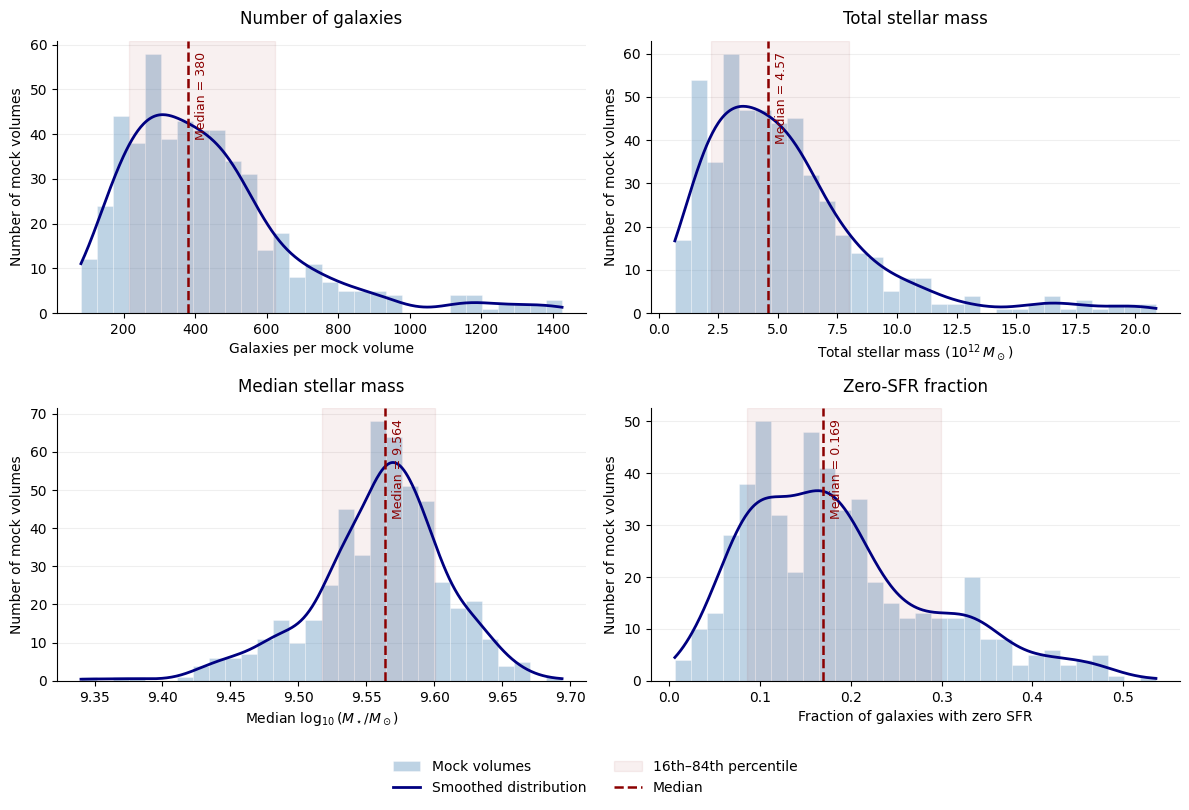

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# --------------------------------------------------
# Configuration
# --------------------------------------------------

plot_specs = [
    {
        "column": "N_galaxies",
        "title": "Number of galaxies",
        "xlabel": "Galaxies per mock volume",
        "scale": 1,
        "precision": 0
    },
    {
        "column": "total_stellar_mass",
        "title": "Total stellar mass",
        "xlabel": r"Total stellar mass ($10^{12}\,M_\odot$)",
        "scale": 1e12,
        "precision": 2
    },
    {
        "column": "median_logMstar",
        "title": "Median stellar mass",
        "xlabel": r"Median $\log_{10}(M_\star/M_\odot)$",
        "scale": 1,
        "precision": 3
    },
    {
        "column": "zero_SFR_fraction",
        "title": "Zero-SFR fraction",
        "xlabel": "Fraction of galaxies with zero SFR",
        "scale": 1,
        "precision": 3
    }
]

# --------------------------------------------------
# Create figure
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8)
)

for ax, spec in zip(axes.flat, plot_specs):

    values = (
        ensemble[spec["column"]]
        .dropna()
        .to_numpy(dtype=float)
        / spec["scale"]
    )

    # Summary statistics
    median = np.median(values)
    p16, p84 = np.percentile(values, [16, 84])

    # Histogram: actual number of mock volumes
    counts, edges, _ = ax.hist(
        values,
        bins=30,
        color="steelblue",
        alpha=0.35,
        edgecolor="white",
        linewidth=0.7,
        label="Mock volumes"
    )

    # Kernel density estimate
    kde = gaussian_kde(values)

    x_grid = np.linspace(
        values.min(),
        values.max(),
        500
    )

    # Convert KDE density into expected bin counts
    bin_width = np.mean(np.diff(edges))

    kde_counts = (
        kde(x_grid)
        * len(values)
        * bin_width
    )

    ax.plot(
        x_grid,
        kde_counts,
        color="navy",
        linewidth=2,
        label="Smoothed distribution"
    )

    # Central 68% interval
    ax.axvspan(
        p16,
        p84,
        color="darkred",
        alpha=0.06,
        label="16th–84th percentile"
    )

    # Median line
    ax.axvline(
        median,
        color="darkred",
        linewidth=1.8,
        linestyle="--",
        label="Median"
    )

    # --------------------------------------------------
    # Numerical median label
    # --------------------------------------------------

    precision = spec["precision"]

    median_label = (
        f"Median = {median:.{precision}f}"
    )

    # Position label near the top of the line
    ax.annotate(
        median_label,
        xy=(median, 0.96),
        xycoords=ax.get_xaxis_transform(),
        xytext=(5, 0),
        textcoords="offset points",
        rotation=90,
        ha="left",
        va="top",
        fontsize=9,
        color="darkred"
    )

    # --------------------------------------------------
    # Formatting
    # --------------------------------------------------

    ax.set_title(
        spec["title"],
        fontsize=12,
        pad=12
    )

    ax.set_xlabel(spec["xlabel"])
    ax.set_ylabel("Number of mock volumes")

    ax.grid(
        axis="y",
        alpha=0.2
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# --------------------------------------------------
# Shared legend
# --------------------------------------------------

handles, labels = axes.flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, -0.015)
)

# No overall figure title:
# the dissertation figure caption will serve
# that purpose.

plt.tight_layout(
    rect=[0, 0.065, 1, 1]
)

# --------------------------------------------------
# Save high-resolution outputs
# --------------------------------------------------

fig.savefig(
    "EAGLE_population_distributions.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "EAGLE_population_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
from scipy.stats import spearmanr

mass_thresholds = [8.0, 8.5, 9.0, 9.5]

threshold_records = []

# Use EXACTLY the same 500 cube origins
# to isolate the effect of changing the mass threshold.

for log_limit in mass_thresholds:

    catalogue = eagle.loc[
        eagle["Mstar_30pkpc"] >= 10**log_limit
    ].copy()

    for _, row in ensemble.iterrows():

        origin = row[
            ["origin_x", "origin_y", "origin_z"]
        ].to_numpy(dtype=float)

        mock = sample_periodic_cube(
            catalogue,
            origin,
            L,
            BOX_SIZE_CMPC
        )

        n = len(mock)

        threshold_records.append({
            "threshold": log_limit,
            "cube_id": int(row["cube_id"]),
            "N_galaxies": n,
            "zero_SFR_fraction": (
                (mock["SFR_30pkpc"] == 0).mean()
                if n > 0 else np.nan
            ),
            "median_logMstar": (
                np.log10(mock["Mstar_30pkpc"]).median()
                if n > 0 else np.nan
            ),
            "total_stellar_mass": mock["Mstar_30pkpc"].sum(),
            "total_SFR": mock["SFR_30pkpc"].sum()
        })

threshold_results = pd.DataFrame(threshold_records)

summary_records = []

for limit, group in threshold_results.groupby("threshold"):

    rho, _ = spearmanr(
        group["N_galaxies"],
        group["zero_SFR_fraction"],
        nan_policy="omit"
    )

    summary_records.append({
        "logM_min": limit,
        "median_N": group["N_galaxies"].median(),
        "N_16": group["N_galaxies"].quantile(0.16),
        "N_84": group["N_galaxies"].quantile(0.84),
        "median_zero_SFR_fraction":
            group["zero_SFR_fraction"].median(),
        "Spearman_rho": rho
    })

threshold_summary = pd.DataFrame(summary_records)

display(threshold_summary.round(3))

threshold_results.to_csv(
    DATA / "EAGLE_mass_threshold_sensitivity.csv",
    index=False
)

,logM_min,median_N,N_16,N_84,median_zero_SFR_fraction,Spearman_rho
0,8.0,1182.5,682.84,1839.80,0.375,0.893
1,8.5,664.0,382.52,1051.44,0.244,0.871
2,9.0,380.5,215.68,622.64,0.169,0.843
3,9.5,215.0,110.84,333.16,0.130,0.808


In [34]:
# ============================================================
# CELL 33
# Stellar-mass threshold sensitivity:
# retained stellar mass and star formation
# ============================================================

import numpy as np
import pandas as pd

MASS_THRESHOLDS = [8.0, 8.5, 9.0, 9.5]

# ------------------------------------------------------------
# 1. Retained fractions across the full EAGLE parent catalogue
# ------------------------------------------------------------

parent_total_mass = eagle["Mstar_30pkpc"].sum()
parent_total_sfr = eagle["SFR_30pkpc"].sum()
parent_count = len(eagle)

box_records = []

for log_limit in MASS_THRESHOLDS:

    selected = eagle.loc[
        eagle["Mstar_30pkpc"] >= 10**log_limit
    ]

    box_records.append({
        "logM_min": log_limit,
        "N_galaxies": len(selected),
        "galaxies_retained_pct":
            100 * len(selected) / parent_count,
        "stellar_mass_retained_pct":
            100 * selected["Mstar_30pkpc"].sum()
            / parent_total_mass,
        "SFR_retained_pct":
            100 * selected["SFR_30pkpc"].sum()
            / parent_total_sfr
    })

box_retention = pd.DataFrame(box_records)

print("FULL EAGLE BOX: RETAINED FRACTIONS")
display(box_retention.round(2))


# ------------------------------------------------------------
# 2. Retained fractions within each of the 500 mock volumes
# ------------------------------------------------------------

cube_records = []

for _, row in ensemble.iterrows():

    origin = row[
        ["origin_x", "origin_y", "origin_z"]
    ].to_numpy(dtype=float)

    # Extract the full parent population above 10^8 Msun
    mock_parent = sample_periodic_cube(
        catalogue=eagle,
        origin=origin,
        side_length=L,
        box_size=BOX_SIZE_CMPC
    )

    reference_mass = mock_parent["Mstar_30pkpc"].sum()
    reference_sfr = mock_parent["SFR_30pkpc"].sum()
    reference_count = len(mock_parent)

    for log_limit in MASS_THRESHOLDS:

        selected = mock_parent.loc[
            mock_parent["Mstar_30pkpc"] >= 10**log_limit
        ]

        cube_records.append({
            "cube_id": int(row["cube_id"]),
            "logM_min": log_limit,

            "galaxies_retained_pct":
                100 * len(selected) / reference_count
                if reference_count > 0 else np.nan,

            "stellar_mass_retained_pct":
                100 * selected["Mstar_30pkpc"].sum()
                / reference_mass
                if reference_mass > 0 else np.nan,

            "SFR_retained_pct":
                100 * selected["SFR_30pkpc"].sum()
                / reference_sfr
                if reference_sfr > 0 else np.nan
        })

cube_retention = pd.DataFrame(cube_records)


# ------------------------------------------------------------
# 3. Summarise variation between mock volumes
# ------------------------------------------------------------

summary_records = []

for log_limit, group in cube_retention.groupby("logM_min"):

    record = {"logM_min": log_limit}

    for column in [
        "galaxies_retained_pct",
        "stellar_mass_retained_pct",
        "SFR_retained_pct"
    ]:

        values = group[column].dropna()

        record[column + "_median"] = values.median()
        record[column + "_p16"] = values.quantile(0.16)
        record[column + "_p84"] = values.quantile(0.84)

    summary_records.append(record)

retention_summary = pd.DataFrame(summary_records)

print("\n500 MOCK VOLUMES: RETAINED FRACTIONS")
display(retention_summary.round(2))


# ------------------------------------------------------------
# 4. Save results
# ------------------------------------------------------------

box_retention.to_csv(
    DATA / "EAGLE_box_mass_threshold_retention.csv",
    index=False
)

cube_retention.to_csv(
    DATA / "EAGLE_cube_mass_threshold_retention.csv",
    index=False
)

retention_summary.to_csv(
    DATA / "EAGLE_mass_threshold_retention_summary.csv",
    index=False
)

print("\nRetention analysis completed and saved.")

FULL EAGLE BOX: RETAINED FRACTIONS


,logM_min,N_galaxies,galaxies_retained_pct,stellar_mass_retained_pct,SFR_retained_pct
0,8.0,40076,100.00,100.000000,100.000000
1,8.5,22580,56.34,98.180000,97.290001
2,9.0,13200,32.94,95.029999,92.480003
3,9.5,7241,18.07,88.709999,81.459999



500 MOCK VOLUMES: RETAINED FRACTIONS


,logM_min,galaxies_retained_pct_median,galaxies_retained_pct_p16,galaxies_retained_pct_p84,stellar_mass_retained_pct_median,stellar_mass_retained_pct_p16,stellar_mass_retained_pct_p84,SFR_retained_pct_median,SFR_retained_pct_p16,SFR_retained_pct_p84
0,8.0,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
1,8.5,56.05,54.07,57.83,98.09,97.64,98.38,97.47,96.32,98.03
2,9.0,32.72,30.75,34.47,94.83,93.77,95.53,92.23,90.05,93.71
3,9.5,17.84,16.01,19.11,88.37,85.79,89.63,80.85,76.49,83.63



Retention analysis completed and saved.


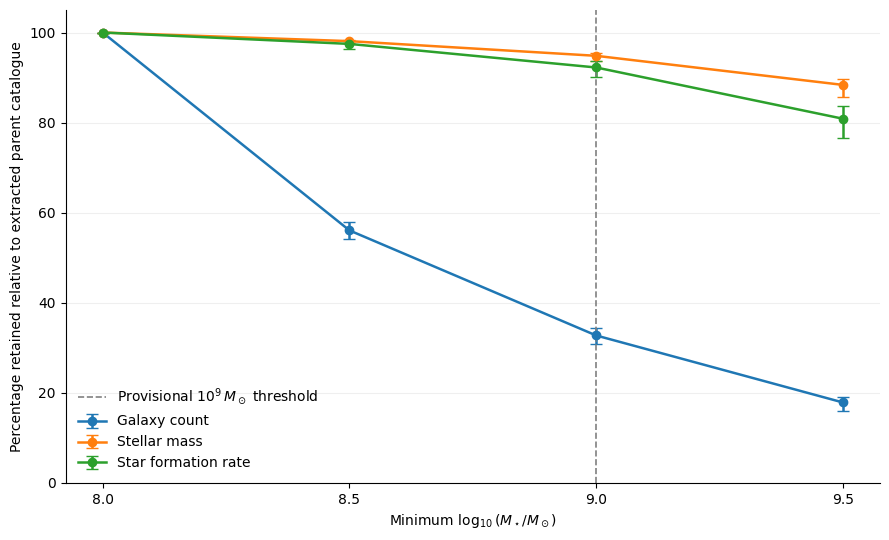

In [35]:
# ============================================================
# CELL 34
# Visualise galaxy, stellar-mass and SFR retention
# ============================================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5.5))

properties = [
    ("galaxies_retained_pct", "Galaxy count"),
    ("stellar_mass_retained_pct", "Stellar mass"),
    ("SFR_retained_pct", "Star formation rate")
]

for column, label in properties:

    medians = retention_summary[
        column + "_median"
    ].to_numpy()

    lower = retention_summary[
        column + "_p16"
    ].to_numpy()

    upper = retention_summary[
        column + "_p84"
    ].to_numpy()

    ax.errorbar(
        retention_summary["logM_min"],
        medians,
        yerr=[
            medians - lower,
            upper - medians
        ],
        marker="o",
        markersize=6,
        linewidth=1.8,
        capsize=4,
        label=label
    )

# Indicate our provisional threshold
ax.axvline(
    9.0,
    color="grey",
    linestyle="--",
    linewidth=1.2,
    label=r"Provisional $10^9\,M_\odot$ threshold"
)

ax.set_xlabel(
    r"Minimum $\log_{10}(M_\star/M_\odot)$"
)

ax.set_ylabel(
    "Percentage retained relative to extracted parent catalogue"
)

ax.set_ylim(0, 105)

ax.set_xticks(MASS_THRESHOLDS)

ax.grid(
    axis="y",
    alpha=0.2
)

ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

fig.savefig(
    "EAGLE_stellar_mass_threshold_retention.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "EAGLE_stellar_mass_threshold_retention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
properties = [
    "N_galaxies",
    "median_logMstar",
    "median_SFR",
    "zero_SFR_fraction",
    "total_stellar_mass",
    "total_SFR"
]

summary_rows = []

for name in properties:

    values = ensemble[name].dropna()

    summary_rows.append({
        "Property": name,
        "Median": values.median(),
        "16th percentile": values.quantile(0.16),
        "84th percentile": values.quantile(0.84),
        "Minimum": values.min(),
        "Maximum": values.max()
    })

ensemble_summary = pd.DataFrame(summary_rows)

display(ensemble_summary)

,Property,Median,16th percentile,84th percentile,Minimum,Maximum
0,N_galaxies,3.805000e+02,2.156800e+02,6.226400e+02,8.100000e+01,1.426000e+03
1,median_logMstar,9.563968e+00,9.517296e+00,9.600317e+00,9.340024e+00,9.693915e+00
2,median_SFR,1.523377e-01,1.005304e-01,1.862919e-01,0.000000e+00,2.489420e-01
3,zero_SFR_fraction,1.692781e-01,8.568421e-02,2.989430e-01,6.172840e-03,5.361184e-01
4,total_stellar_mass,4.570324e+12,2.182685e+12,7.972172e+12,6.721946e+11,2.087515e+13
5,total_SFR,1.564683e+02,8.629305e+01,2.464690e+02,2.306959e+01,4.884771e+02


In [30]:
ensemble_path = DATA / "EAGLE_500_periodic_mock_volumes.csv"

ensemble.to_csv(
    ensemble_path,
    index=False
)

ensemble_config = {
    "simulation": SIMULATION,
    "snapshot": SNAPSHOT,
    "number_of_cubes": N_CUBES,
    "random_seed": ENSEMBLE_SEED,
    "stellar_mass_threshold_msun": float(MASS_MIN),
    "cube_side_comoving_mpc": float(L),
    "cube_volume_comoving_mpc3": float(V90),
    "simulation_box_side_comoving_mpc": BOX_SIZE_CMPC,
    "sampling": "uniform random origins with periodic wrapping",
    "overlap_allowed": True
}

with open(
    DATA / "EAGLE_500_periodic_mock_volumes_config.json",
    "w"
) as f:
    json.dump(ensemble_config, f, indent=2)

print("Saved:", ensemble_path)

Saved: data/EAGLE_500_periodic_mock_volumes.csv


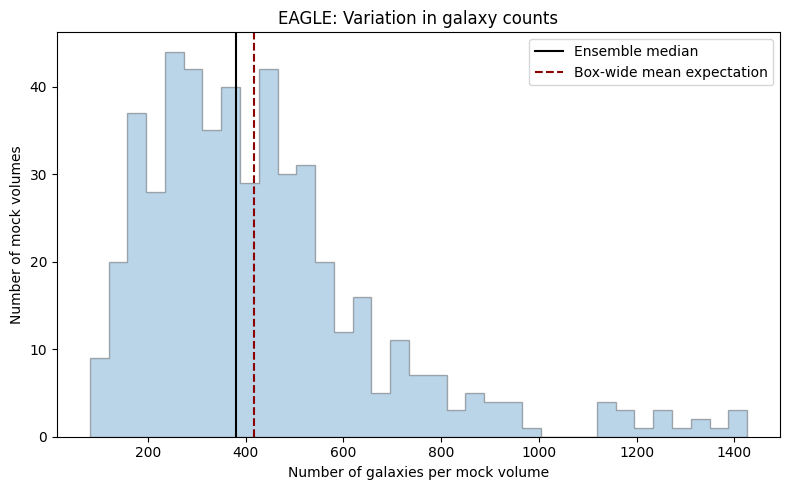

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    ensemble["N_galaxies"],
    bins=35,
    histtype="stepfilled",
    alpha=0.3,
    edgecolor="black"
)

ax.axvline(
    ensemble["N_galaxies"].median(),
    color="black",
    linewidth=1.5,
    label="Ensemble median"
)

ax.axvline(
    threshold_df.loc[
        threshold_df["logM_limit"] == 9.0,
        "expected_N_mock"
    ].iloc[0],
    color="darkred",
    linestyle="--",
    linewidth=1.5,
    label="Box-wide mean expectation"
)

ax.set_xlabel("Number of galaxies per mock volume")
ax.set_ylabel("Number of mock volumes")
ax.set_title("EAGLE: Variation in galaxy counts")

ax.legend()
plt.tight_layout()
plt.show()

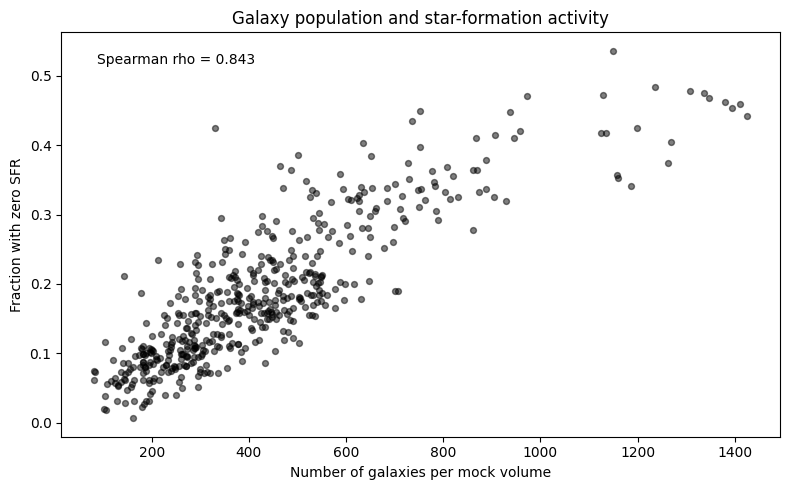

Spearman correlation: 0.8428
Nominal p-value: 4.345e-136


In [32]:
from scipy.stats import spearmanr

x = ensemble["N_galaxies"]
y = ensemble["zero_SFR_fraction"]

rho, p_value = spearmanr(x, y)

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    x,
    y,
    s=18,
    alpha=0.5,
    color="black"
)

ax.set_xlabel("Number of galaxies per mock volume")
ax.set_ylabel("Fraction with zero SFR")
ax.set_title("Galaxy population and star-formation activity")

ax.text(
    0.05,
    0.95,
    f"Spearman rho = {rho:.3f}",
    transform=ax.transAxes,
    va="top"
)

plt.tight_layout()
plt.show()

print(f"Spearman correlation: {rho:.4f}")
print(f"Nominal p-value: {p_value:.4g}")

In [33]:
mass_bins = [
    (9.0, 9.5),
    (9.5, 10.0),
    (10.0, 10.5),
    (10.5, np.inf)
]

records = []

for _, cube in ensemble.iterrows():

    origin = cube[
        ["origin_x", "origin_y", "origin_z"]
    ].to_numpy(dtype=float)

    mock = sample_periodic_cube(
        eagle_science,
        origin,
        L,
        BOX_SIZE_CMPC
    )

    for lower, upper in mass_bins:

        subset = mock[
            (mock["logMstar"] >= lower)
            & (mock["logMstar"] < upper)
        ]

        records.append({
            "cube_id": int(cube["cube_id"]),
            "N_galaxies": len(mock),
            "mass_bin": f"{lower:.1f}–{upper:.1f}",
            "N_in_bin": len(subset),
            "zero_SFR_fraction": (
                (subset["SFR_30pkpc"] == 0).mean()
                if len(subset) > 0 else np.nan
            )
        })

mass_bin_results = pd.DataFrame(records)

for mass_bin, group in mass_bin_results.groupby("mass_bin"):

    valid_group = group[
        group["N_in_bin"] >= 10
    ].dropna()

    rho, p = spearmanr(
        valid_group["N_galaxies"],
        valid_group["zero_SFR_fraction"]
    )

    print(
        f"{mass_bin}: "
        f"rho={rho:.3f}, "
        f"cubes={len(valid_group)}"
    )

10.0–10.5: rho=0.696, cubes=499
10.5–inf: rho=0.561, cubes=484
9.0–9.5: rho=0.838, cubes=500
9.5–10.0: rho=0.799, cubes=500
